In [27]:
#load libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.font_manager as fm
import glob
import string
from tabulate import tabulate
import os
from pathlib import Path
import shutil
import geopandas as gpd
from shapely.geometry import Point, Polygon, LineString, box
from tqdm import tqdm
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors
from matplotlib.colors import TwoSlopeNorm
import math
import time
from shapely.ops import unary_union
import seaborn as sns
from scipy.spatial import cKDTree
import matplotlib.cm as cm
from matplotlib.patches import Circle
from collections import defaultdict
import pyomo.environ as pyo
import gurobipy as gp
import osmnx as ox, networkx as nx
from osmnx.distance import nearest_nodes
from descartes import PolygonPatch
import requests
import matplotlib.colors as colors
import pickle
from datetime import datetime
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

today = datetime.today().strftime("%Y%m%d")

In [28]:
ROOT_DIR = Path.cwd()
DATA_DIR = ROOT_DIR / 'intermediate_result'
RESULTS_DIR = ROOT_DIR / 'results'

In [29]:
gdf_bogun = gpd.read_file(DATA_DIR / 'gdf_bogun.gpkg', encoding="utf-8-sig")
gdf_bogun.index = gdf_bogun.index.astype(str)
loc_bogun_filtered = pd.read_csv(DATA_DIR / 'loc_bogun_filtered.csv', encoding="utf-8-sig")
loc_bogun_filtered['시군구코드'] = loc_bogun_filtered["EMD_CD"].astype(str).str[:5]

In [30]:
def load_selected_facilities(mode, N, LAMBDA_, T, base_dir = RESULTS_DIR / "optimization_results"):
    tag_map = {"free": "free", "sgg_fixed": "sgg_fixed", "sgg_relaxed": "sgg_relaxed"}
    tag = tag_map[mode]
    pattern = f"*_{tag}_N{N}_lambda{LAMBDA_}_T{T}.pkl"
    candidates = sorted((Path(base_dir).glob(pattern)),
                        key=lambda p: p.stat().st_mtime, reverse=True)
    if not candidates:
        raise FileNotFoundError(f"No file matched: {pattern} in {base_dir}")
    path = candidates[0]
    with open(path, "rb") as f:
        data = pickle.load(f)
    return data, path

In [31]:
def load_selected_facilities_revised(mode, T, LSCM, timestep, start, min_equity, min_efficiency, var, base_dir = RESULTS_DIR / "optimization_results"):
    tag_map = {"free": "free", "sgg_fixed": "sgg_fixed", "sgg_relaxed": "sgg_relaxed"}
    tag = tag_map[mode]
    pattern = f"*_{tag}_T{T}_{LSCM}_timestep{timestep}_start{start}_{min_equity}_{min_efficiency}_var{var}.pkl"
    candidates = sorted((Path(base_dir).glob(pattern)),
                        key=lambda p: p.stat().st_mtime, reverse=True)
    if not candidates:
        raise FileNotFoundError(f"No file matched: {pattern} in {base_dir}")
    path = candidates[0]
    with open(path, "rb") as f:
        data = pickle.load(f)
    return data, path

In [32]:
lambda_ = 0.5
mode = "free"
timestep = 7
start = 0
min_equity = 8000
min_efficiency = 12.0
LSCM = "LSCM2"
var = 0.5

In [33]:
selected, p = load_selected_facilities_revised(mode, T=0.5, LSCM = LSCM, timestep=timestep, start = start, min_equity = min_equity, min_efficiency = min_efficiency, var = var)
selected_base, p_base = load_selected_facilities(mode, N=553, LAMBDA_ = lambda_, T = 0.5)

In [34]:
gdf_bogun_sol = {}
for t in range(timestep + 1):
    gdf_bogun_sol[t] = gdf_bogun.loc[gdf_bogun.index.isin(selected['activated_facilities'][t])]
# 기존 static solution과 비교
gdf_bogun_sol['base'] = gdf_bogun.loc[gdf_bogun.index.isin(selected_base)]

gdf_bogun_sol_new = {}
for t in range(timestep + 1):
    gdf_bogun_sol_new[t] = gdf_bogun.loc[gdf_bogun.index.isin(selected['selected_facilities'][t])]
# 기존 static solution과 비교
gdf_bogun_sol_new['base'] = gdf_bogun.loc[gdf_bogun.index.isin(selected_base)]

In [35]:
import math
import pandas as pd

def recompute_grid_accessibility(
    selected_facilities,
    grid_to_inst,
    a_dict,
    Cij
):
    selected_set = set(selected_facilities)

    records = []

    for i, inst_dict in grid_to_inst.items():
        a_i = a_dict[i]

        # 선택된 시설 중 격자 i에 영향 주는 후보
        candidates = [
            j for j in inst_dict.keys()
            if j in selected_set
        ]

        chosen_j = None
        z_i = 0.0

        for j in candidates:
            # j보다 가까운 선택 시설이 있으면 탈락
            closer = Cij.get((i, j), [])
            if any(c in selected_set for c in closer):
                continue
            chosen_j = j
            z_i = inst_dict[j]
            break  # 하나만 허용

        p_i = math.sqrt(a_i + z_i)

        records.append({
            "grid_id": i,
            "a_before": a_i,
            "z": z_i,
            "a_after": a_i + z_i,
            "delta": p_i - math.sqrt(a_i),
            "chosen_facility": chosen_j
        })

    return pd.DataFrame(records)

In [36]:
path = Path(DATA_DIR / "Cij.pkl")
with open(path, "rb") as f:
    Cij = pickle.load(f)

path = Path(DATA_DIR / "a_dict.pkl")
with open(path, "rb") as f:
    a_dict = pickle.load(f)

path = Path(DATA_DIR / "grid_to_inst.pkl")
with open(path, "rb") as f:
    grid_to_inst = pickle.load(f)

In [37]:
gdf_grid_pop = pd.read_csv(DATA_DIR / 'gdf_grid_pop.csv')
gdf_emd = pd.read_csv(DATA_DIR / 'gdf_emd.csv')

In [38]:
from shapely import wkt
gdf_grid_pop['grid_centroid'] = gdf_grid_pop['grid_centroid'].apply(wkt.loads)
gdf_grid_pop['geometry'] = gdf_grid_pop['geometry'].apply(wkt.loads)
gdf_grid_pop = gpd.GeoDataFrame(
    gdf_grid_pop,
    geometry="geometry",
    crs="EPSG:5179"
)

gdf_emd['geometry'] = gdf_emd['geometry'].apply(wkt.loads)
gdf_emd = gpd.GeoDataFrame(
    gdf_emd,
    geometry="geometry",
    crs="EPSG:5179"
)   

In [39]:
for t in range(timestep + 1):
    print(len(selected['selected_facilities'][t]), len(selected['activated_facilities'][t]))

293 293
172 465
88 553
60 320
60 208
60 180
60 180
60 180


In [40]:
df_grid={}
gdf_grid_pop.index = gdf_grid_pop.index.astype(str)
for t in range(0, timestep + 1):
    df_grid[t + 2023] = recompute_grid_accessibility(selected['activated_facilities'][t], grid_to_inst, a_dict, Cij)
    df_grid[t + 2023]["grid_id"] = df_grid[t + 2023]["grid_id"].astype(str)
    df_grid[t + 2023] = df_grid[t + 2023].merge(gdf_grid_pop, left_on = "grid_id", right_index = True, how = 'inner')
    df_grid[t + 2023] = df_grid[t + 2023].drop(columns = ['GRID_500M_', '법정동코드', 'node_id', 'offset_to_node_m'])
    df_grid[t + 2023] = gpd.GeoDataFrame(
        df_grid[t + 2023],
        geometry = 'geometry',
        crs = gdf_grid_pop.crs
    )
    df_grid[t + 2023]['vulnerable'] = (df_grid[t + 2023]['a_before'] < 0.5)
    df_grid[t + 2023]['resolved'] = (df_grid[t + 2023]['vulnerable'] & (df_grid[t + 2023]['a_after'] > 0.5))
    df_grid[t + 2023]['improved accessibility'] = df_grid[t + 2023]['adjusted_population'] * df_grid[t + 2023]['delta']

In [41]:
# 비교군 - 기존 base solution
df_grid_base = recompute_grid_accessibility(selected_base, grid_to_inst, a_dict, Cij)
df_grid_base.index = df_grid_base.index.astype(str)
df_grid_base = df_grid_base.merge(gdf_grid_pop, left_on = "grid_id", right_index = True, how = 'inner')
df_grid_base = df_grid_base.drop(columns = ['GRID_500M_', '법정동코드', 'node_id', 'offset_to_node_m'])
df_grid_base = gpd.GeoDataFrame(
    df_grid_base,
    geometry = 'geometry',
    crs = gdf_grid_pop.crs
)
df_grid_base['vulnerable'] = (df_grid_base['a_before'] < 0.5)
df_grid_base['resolved'] = (df_grid_base['vulnerable'] & (df_grid_base['a_after'] > 0.5))
df_grid_base['improved accessibility'] = df_grid_base['adjusted_population'] * df_grid_base['delta']

In [42]:
result_df = []

resolved_cnt = df_grid_base.loc[
        (df_grid_base["vulnerable"] == True) &
        (df_grid_base["resolved"] == True)
].shape[0]

covered_cnt = df_grid_base.loc[
        (df_grid_base["vulnerable"] == True) &
        (df_grid_base["z"] > 0.001)
].shape[0]

accessibility_improve = int((df_grid_base['delta'] * df_grid_base['adjusted_population']).sum())

result_df.append({
        "연도": "base",
        "해소 취약격자 개수": resolved_cnt,
        "접근성 상승 취약격자 개수": covered_cnt,
        "인구 고려 접근성 향상" : accessibility_improve
    })

In [43]:
for t in range(timestep + 1):
    year = t + 2023
    df_year = df_grid[year]

    resolved_cnt = df_year.loc[
        (df_year["vulnerable"] == True) &
        (df_year["resolved"] == True)
    ].shape[0]

    covered_cnt = df_year.loc[
        (df_year["vulnerable"] == True) &
        (df_year["z"] > 0.001)
    ].shape[0]

    accessibility_improve = int((df_year['delta'] * df_year['adjusted_population']).sum())

    result_df.append({
        "연도": year,
        "해소 취약격자 개수": resolved_cnt,
        "접근성 상승 취약격자 개수": covered_cnt,
        "인구 고려 접근성 향상" : accessibility_improve
    })

result_df = pd.DataFrame(result_df)
result_df

,연도,해소 취약격자 개수,접근성 상승 취약격자 개수,인구 고려 접근성 향상
0,base,8283,9988,169893
1,2023,3269,4587,65504
2,2024,6113,7983,116135
3,2025,8191,9887,150790
4,2026,8146,9639,134015
5,2027,8092,9485,123438
6,2028,8052,9391,120111
7,2029,8052,9391,120111
8,2030,8052,9391,120111


In [44]:
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import BoundaryNorm
from matplotlib.patches import Patch
import numpy as np

In [45]:
emd_access = {}
gdf_emd_access = {}
for t in range(timestep + 1):
    emd_access[t] = df_grid[t+2023].groupby("EMD_CD")["delta"].mean().reset_index(name="access_sum")
    gdf_emd_access[t] = gdf_emd.merge(emd_access[t], on="EMD_CD", how = "left").fillna({"access_sum": 0})

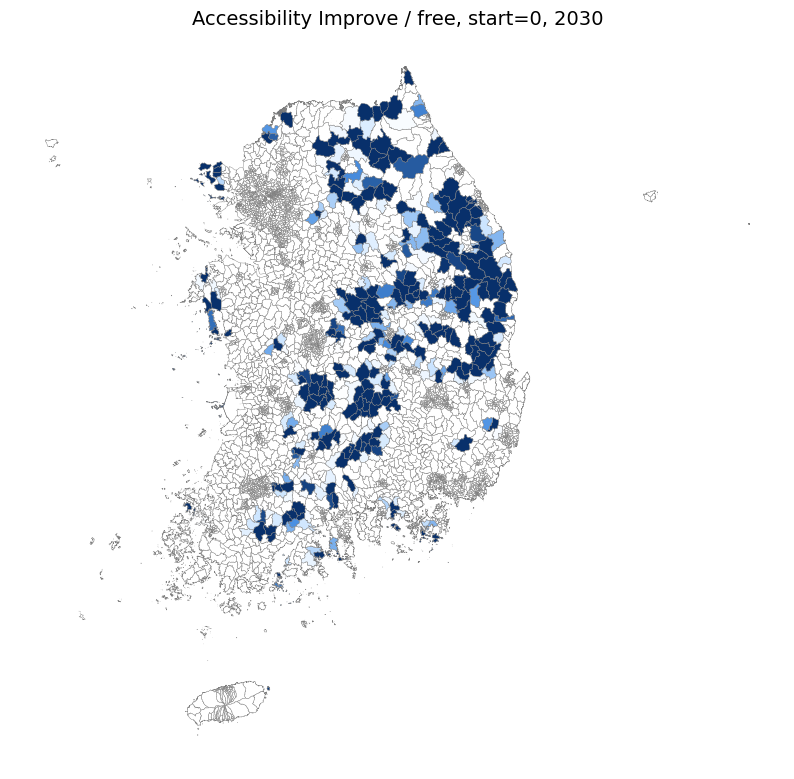

In [46]:
from matplotlib.colors import LinearSegmentedColormap

cmap = LinearSegmentedColormap.from_list(
    "white_to_blue",
    ["#ffffff", "#cce5ff", "#4a90e2", "#08306b"]
)

fig, ax = plt.subplots(figsize=(10, 12))

vmax = max(np.abs(gdf_emd_access[y]["access_sum"]).quantile(0.95) for y in range(timestep + 1))
vmin = 0

year = 7
gdf_emd_access[year].plot(
    column="access_sum",
    cmap=cmap,
    vmin=vmin,
    vmax=vmax,
    legend=False,
    # legend_kwds={'shrink' : 0.6},
    edgecolor="gray",
    linewidth=0.3,
    ax=ax
)

ax.set_title(f"Accessibility Improve / {mode}, start={start}, {year + 2023}", fontsize=14)
ax.axis("off")
plt.show()

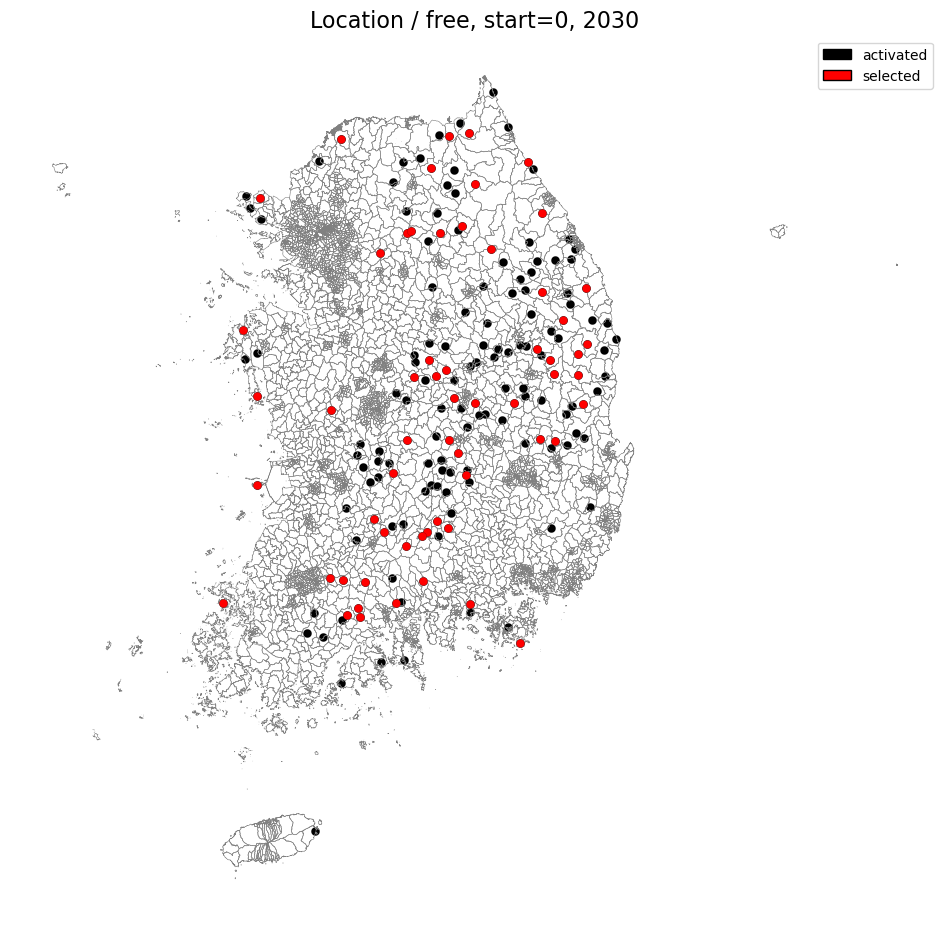

In [53]:
fig, ax = plt.subplots(figsize=(12, 14))

# 보건소
t=7

gdf_bogun_sol[t].plot(
    ax=ax,
    facecolor='black',
    edgecolor='black',
    linewidth=0.1,
    alpha=1.0,
    zorder = 2
)

gdf_bogun_sol_new[t].plot(
    ax=ax,
    facecolor='red',
    edgecolor='black',
    linewidth=0.1,
    alpha=1.0,
    zorder = 10 
)

legend_elements = [
    Patch(facecolor='black',  edgecolor='black', label='activated'),
    Patch(facecolor='red',   edgecolor='black', label='selected'),
]

ax.legend(
    handles=legend_elements,
    loc='upper right',
    fontsize=10,
    title_fontsize=11
)

# 읍면동 경계
gdf_emd.boundary.plot(
    ax=ax,
    linewidth=0.4,
    edgecolor='gray'
)

ax.set_title(f"Location / {mode}, start={start}, {t + 2023}", fontsize=16)
ax.axis('off')

plt.show()

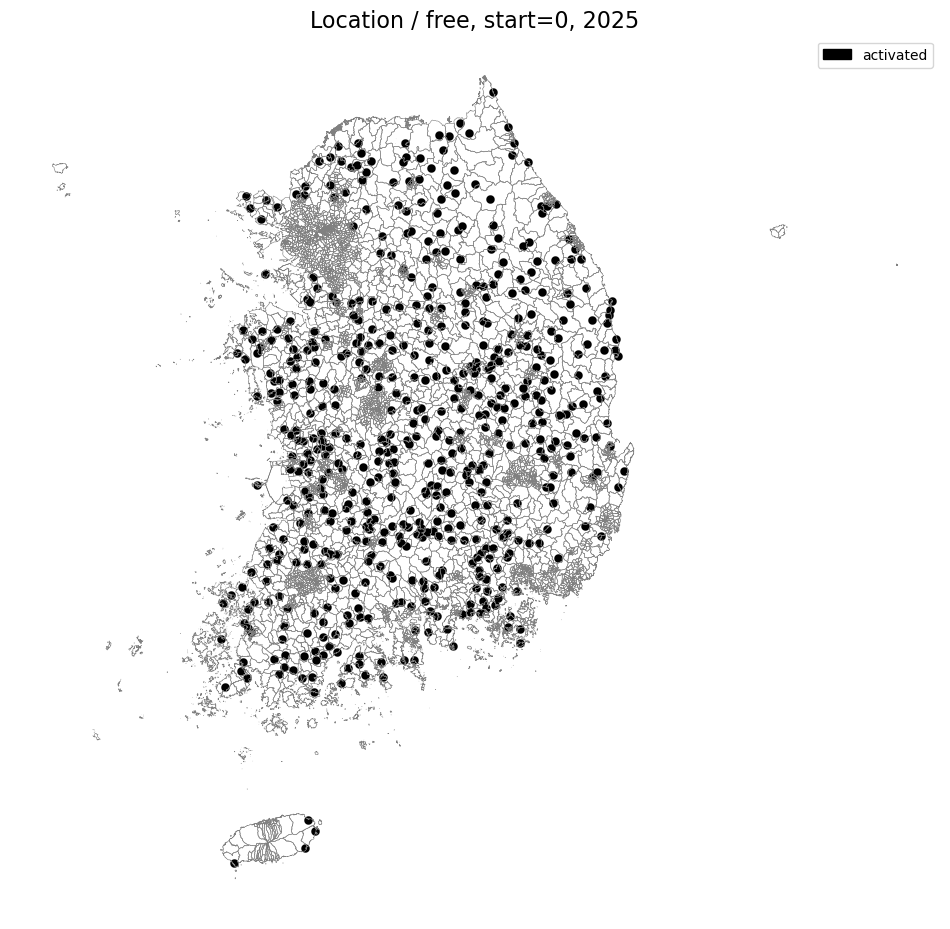

In [48]:
fig, ax = plt.subplots(figsize=(12, 14))

# 보건소
t=2

gdf_bogun_sol[t].plot(
    ax=ax,
    facecolor='black',
    edgecolor='black',
    linewidth=0.1,
    alpha=1.0,
    zorder = 2
)


legend_elements = [
    Patch(facecolor='black',  edgecolor='black', label='activated'),
]

ax.legend(
    handles=legend_elements,
    loc='upper right',
    fontsize=10,
    title_fontsize=11
)

# 읍면동 경계
gdf_emd.boundary.plot(
    ax=ax,
    linewidth=0.4,
    edgecolor='gray'
)

ax.set_title(f"Location / {mode}, start={start}, {t + 2023}", fontsize=16)
ax.axis('off')

plt.show()